[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/arvidl/BMED365-2027/blob/main/Lab4-Comp-Imag/Kiwi-challenge/notebooks/05-kiwi-promptable-foundation-models.ipynb)

# Promptable Vision Foundation Models on 7T MRI — ViT Token Physics, Patch-Zooming, 3D Slice Memory & Neurosymbolic Seed Counting

*BMED365 — Computational Imaging, Modeling and AI in Biomedicine (Spring 2027)*  
*Updated by Arvid Lundervold — runs locally with `uv` (`bmed365-2027` kernel) or in Google Colab*

> **Kiwi Challenge Notebook Sequence (`Lab4-Comp-Imag/Kiwi-challenge`):**
> 0. `00-kiwi-dicom-to-nifti.ipynb` — History of medical image formats (`XITE/BIFF` → `DICOM` → `NIfTI` & `BIDS`) & converting the 128 Bruker 7T DICOM slices
> 1. `01-kiwi-explore.ipynb` — 3D NIfTI headers, physical voxel geometry & coordinate systems
> 2. `02-kiwi-seeds-explore.ipynb` — 2D single-slice filtering, thresholding, unsupervised K-means & the Dagstuhl/CUHK 3D variational milestone
> 3. `03-kiwi-paradigms-and-verification.ipynb` — Full 3D segmentation ladder, quantitative "lesion load", Curated 3D Micro-GT scoring & the **4-Panel Semi-Verifiability Dashboard**
> 4. `03b-kiwi-interactive-gt-and-interrater.ipynb` — Interactive 3D Jupyter-Widget delineation, personalized Ground Truth (`MyStuff/`), **Inter-Rater Variability**, **Panoptic Quality ($\text{PQ}$)** & **STAPLE Consensus**
> 5. `04-kiwi-semantic-vs-instance.ipynb` — Semantic, Instance & Panoptic 3D definitions + supervised PyTorch 3D Semantic vs. Multi-Task Instance U-Nets
> 6. **`05-kiwi-promptable-foundation-models.ipynb` (this workshop)** — Live **`SAM 2.1` vs. `MedSAM`** neural inference via Hugging Face `transformers`: ViT token-stride physics, **Patch-Zooming**, **1-Click `Sam2VideoModel` 3D memory propagation**, and a **zero-training neurosymbolic whole-kiwifruit 3D seed census** *(companion guide: [`../docs/promptable-foundation-models.md`](../docs/promptable-foundation-models.md) | [Printable PDF](../docs/promptable-foundation-models.pdf))*
> 7. [`06-kiwi-frontier-ai-paradigms.ipynb`](./06-kiwi-frontier-ai-paradigms.ipynb) — Frontier AI capstone: **3D Self-Supervised Learning (`SSL`)**, **Selective State-Space Models (`3D U-Mamba`)**, **Conditional Flow-Matching Diffusion**, & **Differentiable Neurosymbolic AI (`LTN`)** *([guide](../docs/frontier-ai-paradigms.md) | [Printable PDF](../docs/frontier-ai-paradigms.pdf))*

---

## Learning Outcomes & Foundation-Model Glossary

### Learning Objectives (MSc & PhD Biomedical Curriculum)
- **MSc Core Competencies:**
  1. **Stuff Bias vs. Micro-Instance Prompting:** Observe why unprompted "Segment Everything" grids segment macroscopic **Stuff** (*peel*, *pericarp*, *columella*) while missing `4–6 px` **Things** (*seeds*, *cerebral microbleeds*, *nuclei*).
  2. **Patch-Zooming & Prompt Modality (`MedSAM` vs. `SAM 2.1`):** Quantify why `MedSAM` fails on single-point clicks (`IoU = 0.037`) yet jumps `16×` (`IoU = 0.602`) when given zoomed bounding boxes, and why `SAM 2.1`'s Hiera FPN (`stride-4` skip features) excels on both clicks and boxes.
  3. **Interactive 1-Click 3D Curation vs. Zero-Training Whole-Organ Census:** Use `Sam2VideoModel` streaming memory to turn **1 click per seed** into a 3D `uint16` segmentation (`PQ = 0.500`), and combine botanical priors with `SAM 2.1` confidence tokens (`iou_scores`) to count seeds across the entire `256 × 256 × 128` berry with **zero kiwi training labels**.
- **PhD & Research-Track Extensions:**
  1. **ViT Nyquist Token Footprint ($\Delta_{\text{tok}}$):** Relate encoder patch stride $s_{\text{enc}}$ and input field-of-view $N_{\text{FOV}}$ to physical specimen resolution $\Delta_{\text{tok}} = \frac{N_{\text{FOV}}}{N_{\text{grid}}}\Delta x$, proving when Patch-Zooming is mathematically required.
  2. **Space-as-Time Memory Drift in Anisotropic 3D MRI:** Diagnose vertical $z$-axis instance fusion when video transformers track across thick slices ($\Delta z = 0.50\text{ mm} > 2\Delta x$), and suppress drift via physical horizon gating ($\lvert z - z_0 \rvert \le \lceil R_z / \Delta z \rceil$) + occlusion logits (`object_score_logits`).
  3. **Eliminating Spatial Out-of-Distribution (`OOD`) Shift:** Explain why neurosymbolic `SAM 2.1` generalizes cleanly from equatorial to polar slices (`~1,553` calibrated seeds) where Notebook `04`'s equatorial-trained 3D U-Net suffered polar vascular over-firing (`3,328` raw blobs).

### Compact Glossary: Vision Foundation Models ↔ Clinical Biomedical Imaging

| Term / Symbol | Intuitive Meaning | Mathematical / Architectural Definition | Clinical Biomedical Parallel |
| :--- | :--- | :--- | :--- |
| **Token Footprint ($\Delta_{\text{tok}}$)** | Physical width of 1 ViT patch in the organ | $\Delta_{\text{tok}} = (N_{\text{FOV}} / N_{\text{grid}})\,\Delta x$ (`0.94 mm` full-slice vs. `0.29 mm` zoomed) | Missing `1–2 mm` **cerebral microbleeds** (`CMBs`) or **microcalcifications** in full-FOV ViT encoders |
| **Hiera FPN Skip Features** | High-res spatial shortcuts into the mask decoder | Multi-scale `stride-4` (`256×256`) & `stride-8` (`128×128`) features fused into `SAM 2.1` upsampling | Preserving thin **inter-seed mucilage clefts** or **packed cell membranes** lost by plain `ViT-B/16` (`MedSAM`) |
| **Part–Whole Multi-Mask ($M=3$)** | 3 nested masks for an ambiguous 1-point click | Ordered heads: $m=0$ (*sub-part: seed*), $m=1$ (*part: locule*), $m=2$ (*whole: fruit*) | Disambiguating **necrotic core** vs. **enhancing tumor** vs. **whole FLAIR edema** in glioma `mpMRI` |
| **Streaming Slice Memory** | Treating axial slice $z$ as video frame $t$ | Cross-attention from slice $z$ features to memory-encoded masks at $z \pm 1, z \pm 2$ (`Sam2VideoModel`) | Propagating a radiologist's single-slice lesion contour across a 3D CT/MRI volume (`MedSAM2`) |
| **Confidence & Occlusion Tokens** | Built-in quality & slice-termination heads | Predicted $\hat{\text{IoU}} \in [0,1]$ (`iou_scores`) and presence logit $\ell_{\text{obj}} \in \mathbb{R}$ (`object_score_logits`) | Self-supervised **false-positive rejection** on vessel mimics & stopping tracking at superior/inferior lesion poles |


---

## Step 0 — Cross-Platform Setup, Apple Silicon `MPS` `float32` Hygiene & Foundation Model Loading

> **Cross-Platform Tip (`CUDA` / Apple `MPS` / `CPU` / Google Colab):**  
> Both checkpoints used below — **`facebook/sam2.1-hiera-small`** (`~184 MB`, Apache-2.0) and **`wanglab/medsam-vit-base`** (`~375 MB`, Ma et al., *Nature Communications* 2024) — are **ungated** on Hugging Face and supported natively by `transformers` (`Sam2Model`, `Sam2VideoModel`, `SamModel`), requiring **no Hugging Face login token** and **no custom CUDA compilation**.  
> On **Apple Silicon Macs (`mps`)**, Hugging Face's `SamProcessor` converts Python `float` prompt coordinates into `torch.float64` tensors by default, which `mps` rejects. Our `to_device_fp32(...)` helper below automatically downcasts floating-point prompt tensors to `torch.float32` so the exact same code runs seamlessly on **Linux CUDA**, **macOS M1–M5 MPS**, **Google Colab T4**, and **CPU**.


In [1]:
import json
import sys
import time
import warnings
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy import ndimage as ndi
from scipy.optimize import linear_sum_assignment
from skimage import filters, measure, segmentation

def _ensure_pkg(import_name: str, pip_spec: str | None = None):
    import importlib.util
    if importlib.util.find_spec(import_name) is None:
        import subprocess
        pkg = pip_spec or import_name
        print(f"Installing {pkg} for this session...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

_ensure_pkg("nibabel")
_ensure_pkg("torch")
_ensure_pkg("transformers", "transformers>=4.56.0")

get_ipython().run_line_magic("matplotlib", "inline")
plt.rcParams["figure.dpi"] = 115
warnings.filterwarnings("ignore", message=".*model of type `sam2_video` to instantiate a model of type `sam2`.*")
warnings.filterwarnings("ignore", message=".*memory_attention_rope_theta.*")

import nibabel as nib
import torch
from transformers import (
    Sam2Model,
    Sam2Processor,
    Sam2VideoModel,
    Sam2VideoProcessor,
    SamModel,
    SamProcessor,
)

def get_best_device() -> torch.device:
    if torch.cuda.is_available():
        return torch.device("cuda")
    if hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def to_device_fp32(batch: dict, dev: torch.device) -> dict:
    """Move Hugging Face processor outputs to `dev` while casting float64 -> float32 for Apple MPS compatibility."""
    out = {}
    for k, v in batch.items():
        if isinstance(v, torch.Tensor):
            if v.is_floating_point() and v.dtype == torch.float64:
                v = v.to(dtype=torch.float32)
            out[k] = v if k in ("original_sizes", "reshaped_input_sizes") else v.to(dev)
        else:
            out[k] = v
    return out

DEVICE = get_best_device()
torch.manual_seed(2027)
np.random.seed(2027)

GITHUB_RAW_BASE = "https://raw.githubusercontent.com/arvidl/BMED365-2027/main/Lab4-Comp-Imag/Kiwi-challenge"

def resolve_kiwi_file(rel_path: str) -> Path:
    for cand in [Path("..") / rel_path, Path("Lab4-Comp-Imag/Kiwi-challenge") / rel_path, Path(rel_path)]:
        if cand.exists():
            return cand
    dst = Path(rel_path)
    dst.parent.mkdir(parents=True, exist_ok=True)
    print(f"Downloading {rel_path} from GitHub for Colab session...")
    urllib.request.urlretrieve(f"{GITHUB_RAW_BASE}/{rel_path}", dst)
    return dst

# 1. Load 2005 UiB 7T RARE MRI volume + Curated 3D Micro-GT
nii_img = nib.load(str(resolve_kiwi_file("data/kiwi_20050217191129_131073_RARE_high_res_axial.nii.gz")))
vol = nii_img.get_fdata(dtype=np.float32)
spacing = tuple(float(s) for s in nii_img.header.get_zooms()[:3])  # (0.234375, 0.234375, 0.5) mm
vox_vol_mm3 = float(np.prod(spacing))

gt_full = np.asarray(nib.load(str(resolve_kiwi_file("data/kiwi_micro_gt_labels.nii.gz"))).dataobj, dtype=np.uint16)
gt_meta = json.loads(resolve_kiwi_file("data/kiwi_micro_gt_roi.json").read_text(encoding="utf-8"))
RX0, RX1 = gt_meta["roi_bounds_voxel_xyz"]["x"]  # [128, 208)
RY0, RY1 = gt_meta["roi_bounds_voxel_xyz"]["y"]  # [128, 208)
RZ0, RZ1 = gt_meta["roi_bounds_voxel_xyz"]["z"]  # [56, 72)
SPLIT_Y = 40  # Exact held-out test split y=[168, 208) from Notebook 04 (52 unseen 3D seeds)

# 2. Build whole-fruit mask, anatomical Stuff zones & normalized radial coordinate r / R_fruit
v_sm = ndi.gaussian_filter(vol, sigma=(1.2 / spacing[0], 1.2 / spacing[1], 1.2 / spacing[2]))
fg_r = v_sm > (filters.threshold_otsu(v_sm[::2, ::2, ::2]) * 0.35)
fg_f = np.zeros_like(fg_r)
for z in range(vol.shape[2]):
    fg_f[:, :, z] = ndi.binary_fill_holes(fg_r[:, :, z])
fg_f = ndi.binary_fill_holes(fg_f)
lbl_fg, _ = ndi.label(fg_f)
fruit_mask_full = lbl_fg == (1 + int(np.argmax(np.bincount(lbl_fg.ravel())[1:])))
fruit_interior = ndi.binary_erosion(fruit_mask_full, iterations=4)

p99 = float(np.percentile(vol[fruit_mask_full], 99.0))
vol_norm = np.clip(vol / (p99 + 1e-6), 0.0, 1.25).astype(np.float32)
env_close = ndi.grey_closing(vol_norm, size=(7, 7, 3))
env_local = ndi.gaussian_filter(env_close, sigma=(0.8 / spacing[0], 0.8 / spacing[1], 0.8 / spacing[2])).astype(np.float32)

stuff_full = np.zeros(vol.shape, dtype=np.uint8)
stuff_full[fruit_mask_full] = 1
stuff_full[fruit_interior] = 2
r_over_R_full = np.ones_like(vol_norm, dtype=np.float32)
yy_f, xx_f = np.meshgrid(np.arange(vol.shape[1]), np.arange(vol.shape[0]))
for z in range(vol.shape[2]):
    m = fruit_mask_full[:, :, z]
    if m.sum() < 100:
        continue
    cx, cy = float(xx_f[m].mean()), float(yy_f[m].mean())
    r_px = np.sqrt((xx_f - cx) ** 2 + (yy_f - cy) ** 2)
    r_fruit = float(np.sqrt(m.sum() / np.pi))
    r_over_R_full[:, :, z] = r_px / max(r_fruit, 1.0)
    col_mask = m & (r_px < 0.28 * r_fruit) & (v_sm[:, :, z] < np.percentile(v_sm[:, :, z][m], 55))
    stuff_full[:, :, z][col_mask] = 3

# Extract exact held-out 3D test wedge (80 × 40 × 16) matching Notebook 04
TY0, TY1 = RY0 + SPLIT_Y, RY1
test_vol = vol_norm[RX0:RX1, TY0:TY1, RZ0:RZ1]
test_env = env_local[RX0:RX1, TY0:TY1, RZ0:RZ1]
test_ring = stuff_full[RX0:RX1, TY0:TY1, RZ0:RZ1] == 2
test_inner_pericarp = test_ring & (r_over_R_full[RX0:RX1, TY0:TY1, RZ0:RZ1] >= 0.24) & (r_over_R_full[RX0:RX1, TY0:TY1, RZ0:RZ1] <= 0.62)

def relabel_contiguous(lbl: np.ndarray) -> np.ndarray:
    out = np.zeros_like(lbl, dtype=np.uint16)
    for new_id, old_id in enumerate([int(v) for v in np.unique(lbl) if v > 0], start=1):
        out[lbl == old_id] = new_id
    return out

test_gt = relabel_contiguous(gt_full[RX0:RX1, TY0:TY1, RZ0:RZ1])

# 3. Load ungated SAM 2.1 & MedSAM checkpoints from Hugging Face Hub
t0 = time.perf_counter()
SAM2_ID = "facebook/sam2.1-hiera-small"
sam2_proc = Sam2Processor.from_pretrained(SAM2_ID)
sam2_model = Sam2Model.from_pretrained(SAM2_ID).to(DEVICE).eval()
sam2_vid_proc = Sam2VideoProcessor.from_pretrained(SAM2_ID)
sam2_vid_model = Sam2VideoModel.from_pretrained(SAM2_ID).to(DEVICE).eval()

MEDSAM_ID = "wanglab/medsam-vit-base"
medsam_proc = SamProcessor.from_pretrained(MEDSAM_ID)
medsam_model = SamModel.from_pretrained(MEDSAM_ID).to(DEVICE).eval()

print(f"PyTorch {torch.__version__} | Compute device: {DEVICE}")
print(f"Loaded {SAM2_ID} & {MEDSAM_ID} in {time.perf_counter() - t0:.2f} s")
print(f"Held-out 3D Test Wedge: shape={test_vol.shape} ({int(test_gt.max())} unseen 3D ground-truth seeds)")

PyTorch 2.15.0 | Compute device: mps
Loaded facebook/sam2.1-hiera-small & wanglab/medsam-vit-base in 2.15 s
Held-out 3D Test Wedge: shape=(80, 40, 16) (52 unseen 3D ground-truth seeds)


---

## Step 1 — Why Unprompted Grids Segment *Stuff*, Not 5-Pixel *Things* (ViT Token Physics & Scale Ambiguity)

Before evaluating 3D pipelines, let us inspect **what happens inside the Vision Transformer (`ViT`) encoder and multi-mask decoder** on equatorial slice `z = 64`:

1. **The ViT Patch-Stride Bottleneck ($\Delta_{\text{tok}}$):**  
   Standard `SAM` / `MedSAM` encoders resize an input slice of width $N_{\text{FOV}}$ to $1024 \times 1024$ and tokenize with patch stride $s_{\text{enc}} = 16$, creating a $64 \times 64$ feature grid. On the full `256 × 256` 7T slice ($\Delta x = 0.2344\text{ mm}$), a single ViT feature token covers:

   $$\Delta_{\text{tok}}^{\text{full}} = \frac{256}{64} \times 0.2344\text{ mm} = 0.938\text{ mm} \;\;(\text{4 × 4 MRI pixels!})$$

   Because a kiwifruit seed's minor diameter is only $\approx 1.0\text{--}1.3\text{ mm}$, **an entire seed is barely 1 token wide!** Cropping an $80 \times 40$ sector (*Patch-Zoom*) shrinks $\Delta_{\text{tok}}$ to **$0.293\text{ mm}$**, while `SAM 2.1`'s **Hiera FPN `stride-4` skip features** push spatial resolution down to **$0.073\text{ mm}$**.
2. **Part–Whole Scale Ambiguity (`multimask_output=True`):**  
   When prompted with a **single point** inside a seed, `SAM 2.1` predicts three nested hypotheses: **`m = 0` (sub-part: the individual seed)**, **`m = 1` (part: the radial locule / pericarp sector)**, and **`m = 2` (whole organ: the entire kiwifruit)**. In unprompted grid mode (*"Segment Everything"*), ranking masks by `argmax(iou_scores)` overwhelmingly selects macroscopic **Stuff** ($m = 2$ or $m = 1$, where outer fruit borders have $\hat{\text{IoU}} > 0.95$) rather than tiny **Things**!


Unprompted 8×8 grid (`argmax iou_score` >= 0.70): 52 macro 'Stuff' masks (>200 px) vs. 4 seed-scale masks!
Single seed click (21.5, 4.9) multi-mask IoU predictions -> m=0 (sub-part): 0.800 | m=1 (part): 0.713 | m=2 (whole): 0.012


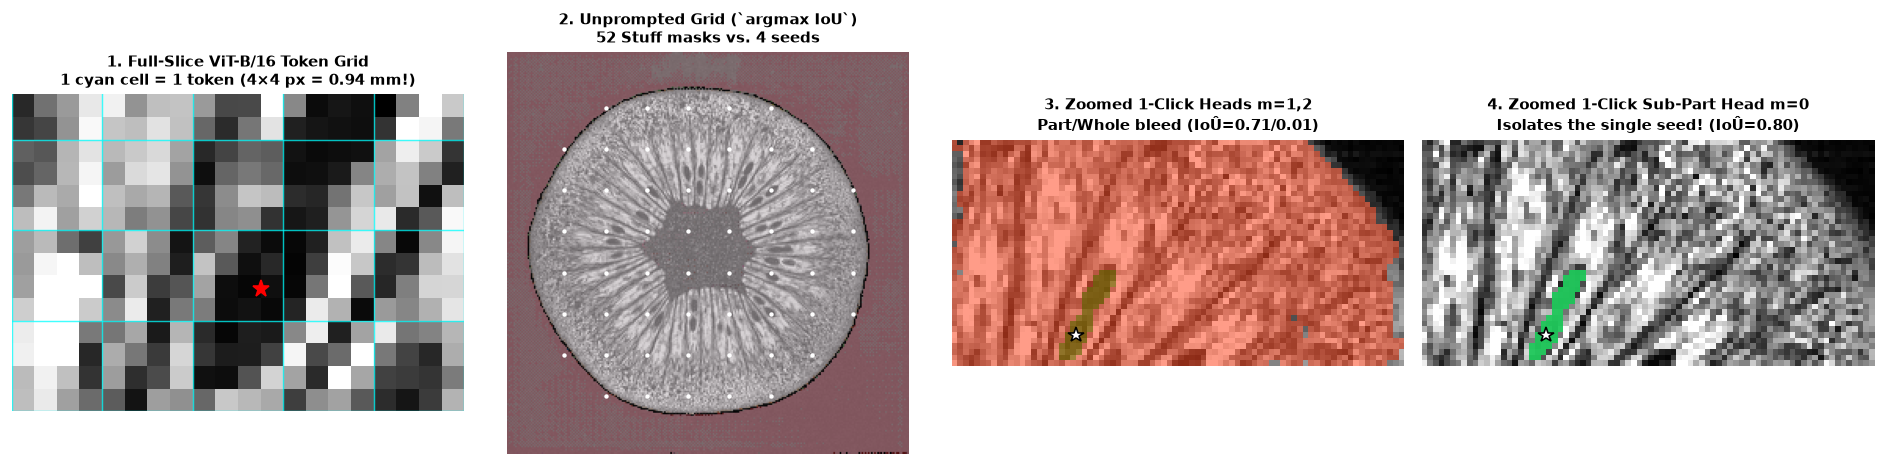

In [2]:
def slice_xy_to_pil(sl_xy: np.ndarray, invert: bool = False) -> Image.Image:
    """Convert (SX, SY) float array in [0, 1] to RGB PIL image (width=SX, height=SY)
    so NIfTI slice coordinate (ix, iy) maps 1-to-1 to prompt coordinate [x=ix, y=iy]."""
    arr = np.clip(sl_xy, 0.0, 1.0)
    if invert:
        arr = 1.0 - arr
    u8 = (arr.T * 255.0).round().astype(np.uint8)
    return Image.fromarray(np.stack([u8, u8, u8], axis=-1))

z_rel = 8  # Equatorial slice z = 64
pil_full_z64 = slice_xy_to_pil(vol_norm[:, :, RZ0 + z_rel])
pil_zoom_z64 = slice_xy_to_pil(test_vol[:, :, z_rel])

# 1. Simulate unprompted "Segment Everything" 8×8 point grid on full 256×256 slice (selecting argmax iou_score)
grid_1d = np.linspace(36, 220, 8)
grid_pts = [[[float(gx), float(gy)]] for gx in grid_1d for gy in grid_1d if fruit_mask_full[int(gx), int(gy), RZ0 + z_rel]]
grid_lbls = [[1] for _ in grid_pts]
raw_grid = sam2_proc(images=pil_full_z64, input_points=[grid_pts], input_labels=[grid_lbls], return_tensors="pt")
in_grid = to_device_fp32(raw_grid, DEVICE)
with torch.no_grad():
    out_grid = sam2_model(
        pixel_values=in_grid["pixel_values"],
        input_points=in_grid["input_points"],
        input_labels=in_grid["input_labels"],
        multimask_output=True,
    )
pm_grid = sam2_proc.post_process_masks(out_grid.pred_masks.cpu(), raw_grid["original_sizes"])[0]  # (N_pts, 3, 256, 256)
iou_grid = out_grid.iou_scores.cpu()[0].numpy()

# Classify what argmax(iou_scores) actually segmented on the 8×8 grid:
stuff_vs_seed_areas = []
stuff_canvas = np.zeros((256, 256, 3), dtype=np.float32)
cmap_tab = plt.get_cmap("tab20")
for k in range(len(grid_pts)):
    best_m = int(np.argmax(iou_grid[k]))
    if iou_grid[k, best_m] < 0.70:
        continue
    m_xy = pm_grid[k, best_m].numpy().T.astype(bool)
    area_px = int(m_xy.sum())
    stuff_vs_seed_areas.append(area_px)
    if area_px > 80:
        stuff_canvas[m_xy.T] = 0.65 * np.array(cmap_tab(k % 20)[:3]) + 0.35 * stuff_canvas[m_xy.T]

n_macro_masks = sum(a > 200 for a in stuff_vs_seed_areas)
n_seed_scale_masks = sum(5 <= a <= 60 for a in stuff_vs_seed_areas)

# 2. Inspect SAM 2.1's 3 nested part–whole ambiguity heads (m=0, 1, 2) for ONE seed click on the zoomed 80×40 ROI
sample_props = [p for p in measure.regionprops(test_gt[:, :, z_rel]) if p.area >= 8]
p_demo = sample_props[len(sample_props) // 2]
cx_d, cy_d = float(p_demo.centroid[0]), float(p_demo.centroid[1])

raw_amb = sam2_proc(images=pil_zoom_z64, input_points=[[[[cx_d, cy_d]]]], input_labels=[[[1]]], return_tensors="pt")
in_amb = to_device_fp32(raw_amb, DEVICE)
with torch.no_grad():
    out_amb = sam2_model(
        pixel_values=in_amb["pixel_values"],
        input_points=in_amb["input_points"],
        input_labels=in_amb["input_labels"],
        multimask_output=True,
    )
pm_amb = sam2_proc.post_process_masks(out_amb.pred_masks.cpu(), raw_amb["original_sizes"])[0][0].numpy()  # (3, H=40, W=80)
iou_amb = out_amb.iou_scores.cpu()[0, 0].numpy()

print(f"Unprompted 8×8 grid (`argmax iou_score` >= 0.70): {n_macro_masks} macro 'Stuff' masks (>200 px) vs. {n_seed_scale_masks} seed-scale masks!")
print(f"Single seed click ({cx_d:.1f}, {cy_d:.1f}) multi-mask IoU predictions -> m=0 (sub-part): {iou_amb[0]:.3f} | m=1 (part): {iou_amb[1]:.3f} | m=2 (whole): {iou_amb[2]:.3f}")

# 4-Panel Visual Demonstration
fig, axes = plt.subplots(1, 4, figsize=(16.5, 4.0))

# Panel 1: Full-slice ViT 4×4 pixel token grid overlaid on zoomed seed neighborhood
zx0, zx1, zy0, zy1 = max(0, int(cx_d) - 10), min(80, int(cx_d) + 10), max(0, int(cy_d) - 10), min(40, int(cy_d) + 10)
axes[0].imshow(test_vol[zx0:zx1, zy0:zy1, z_rel].T, cmap="gray", origin="lower", vmin=0, vmax=1)
for gx_line in range(0, zx1 - zx0 + 1, 4):
    axes[0].axvline(gx_line - 0.5, color="cyan", lw=0.9, alpha=0.75)
for gy_line in range(0, zy1 - zy0 + 1, 4):
    axes[0].axhline(gy_line - 0.5, color="cyan", lw=0.9, alpha=0.75)
axes[0].plot(cx_d - zx0, cy_d - zy0, "r*", ms=11)
axes[0].set_title("1. Full-Slice ViT-B/16 Token Grid\n1 cyan cell = 1 token (4×4 px = 0.94 mm!)", fontsize=9.5, fontweight="bold")
axes[0].axis("off")

# Panel 2: Unprompted 8×8 grid on full 256×256 slice -> Stuff dominance
axes[1].imshow(vol_norm[:, :, RZ0 + z_rel].T, cmap="gray", origin="lower", vmin=0, vmax=1)
axes[1].imshow(stuff_canvas, alpha=0.58, origin="lower")
for pt in grid_pts:
    axes[1].plot(pt[0][0], pt[0][1], "w.", ms=3.5)
axes[1].set_title(f"2. Unprompted Grid (`argmax IoU`)\n{n_macro_masks} Stuff masks vs. {n_seed_scale_masks} seeds", fontsize=9.5, fontweight="bold")
axes[1].axis("off")

# Panel 3: Ambiguous 1-click Head m=2 (Whole/Macro region) vs Head m=0 (Sub-part seed)
axes[2].imshow(test_vol[:, :, z_rel].T, cmap="gray", origin="lower", vmin=0, vmax=1)
ov_m2 = np.zeros((40, 80, 4), dtype=np.float32)
ov_m2[pm_amb[2] > 0] = (1.0, 0.30, 0.15, 0.55)
ov_m2[pm_amb[1] > 0] = (1.0, 0.75, 0.10, 0.45)
axes[2].imshow(ov_m2, origin="lower")
axes[2].plot(cx_d, cy_d, "w*", ms=10, mec="black")
axes[2].set_title(f"3. Zoomed 1-Click Heads m=1,2\nPart/Whole bleed (IoÛ={iou_amb[1]:.2f}/{iou_amb[2]:.2f})", fontsize=9.5, fontweight="bold")
axes[2].axis("off")

axes[3].imshow(test_vol[:, :, z_rel].T, cmap="gray", origin="lower", vmin=0, vmax=1)
ov_m0 = np.zeros((40, 80, 4), dtype=np.float32)
ov_m0[pm_amb[0] > 0] = (0.15, 0.92, 0.42, 0.82)
axes[3].imshow(ov_m0, origin="lower")
axes[3].plot(cx_d, cy_d, "w*", ms=10, mec="black")
axes[3].set_title(f"4. Zoomed 1-Click Sub-Part Head m=0\nIsolates the single seed! (IoÛ={iou_amb[0]:.2f})", fontsize=9.5, fontweight="bold")
axes[3].axis("off")

plt.tight_layout()
plt.show()

### Interpreting Step 1: Token Nyquist Limits & Part–Whole Disambiguation

- **Panel 1 (`Cyan Grid`):** On the full `256 × 256` MRI slice, each `16 × 16` ViT patch covers `4 × 4` native MRI pixels (`0.94 × 0.94 mm`). Notice that the dark seed under the red star spans barely **1 to 1.5 cyan squares** — explaining why naive full-FOV foundation-model calls blur micro-structures!
- **Panel 2 (`Stuff Bias`):** When an unprompted grid ranks multi-mask candidates by `argmax(iou_scores)`, crisp macroscopic boundaries (*whole kiwifruit*, *pericarp*, *central columella*) achieve higher predicted $\hat{\text{IoU}}$ than tiny partial-volume seeds, turning "Segment Everything" into a **semantic Stuff segmenter**.
- **Panels 3 vs. 4 (`Scale-Ambiguity Heads m=0, 1, 2`):** On a zoomed `80 × 40` crop, **Head `m = 0` (finest sub-part)** cleanly isolates the clicked seed, whereas Heads `m = 1, 2` expand into surrounding locular/pericarp structure!

<details>
<summary><b>Check Your Understanding Q1:</b> On a clinical 3D brain MRI (<code>1.0 × 1.0 × 1.0 mm³</code>, <code>256 × 256</code> slices), how many ViT-B/16 tokens wide is a <code>2 mm</code> cerebral microbleed on a full slice versus a <code>64 × 64</code> zoomed ROI patch?</summary>

- **Full `256 × 256` slice** resized to `1024 × 1024` (`64 × 64` token grid): $\Delta_{\text{tok}} = (256 / 64) \times 1.0\text{ mm} = 4.0\text{ mm/token}$ — a `2 mm` microbleed is **only `0.5` tokens wide** (sub-token)!
- **Zoomed `64 × 64` ROI patch** resized to `1024 × 1024`: $\Delta_{\text{tok}} = (64 / 64) \times 1.0\text{ mm} = 1.0\text{ mm/token}$ (**`2.0` tokens wide**, plus `8.0` `stride-4` FPN pixels wide in `SAM 2.1`!).

</details>


---

## Step 2 — 2D Resolution & Prompt Modality Ablation (`MedSAM` vs. `SAM 2.1` on Slice `z = 64`)

Does **domain-specific medical pretraining** (`MedSAM`, trained on 1.57M medical masks) automatically beat a **general-purpose hierarchical foundation model** (`SAM 2.1`) on our 7T MRI seeds? Let us run a controlled $2 \times 2 \times 4$ ablation on the 8 ground-truth seed cross-sections visible on slice `z = 64`, varying:
1. **Model architecture:** `MedSAM` (`ViT-B/16`, no high-res FPN skips, box-trained decoder) vs. `SAM 2.1` (`Hiera-Small` with `stride-4` & `stride-8` FPN skips).
2. **Input field of view:** Full `256 × 256` slice vs. Patch-Zoomed `80 × 40` test wedge.
3. **Prompt geometry:** `1-Point` (`m = 0`), `1-Pos + 4-Neg Ring` (`±1.0 mm` negative points in bright gel), `Tight Box` (`±0.8 px`), and `Box + Center Point` (+ inverted-intensity polarity check `1 - I` to test whether dark-vs-bright foreground polarity affects `SAM 2.1`).


,Model,Input Scope,Prompt Modality,Mean 2D Seed IoU,2D Semantic Dice,Latency (ms)
0,MedSAM,Full 256×256,1-Point,0.037,0.165,266.8
1,MedSAM,Full 256×256,Tight Box,0.277,0.491,235.0
2,MedSAM,Zoom 80×40,1-Point,0.107,0.237,242.6
3,MedSAM,Zoom 80×40,Tight Box,0.602,0.748,239.7
4,SAM 2.1,Full 256×256,1-Point,0.377,0.235,107.3
5,SAM 2.1,Full 256×256,Tight Box,0.570,0.779,90.7
6,SAM 2.1,Zoom 80×40,1-Point,0.520,0.603,83.4
7,SAM 2.1,Zoom 80×40,1-Pos + 4-Neg Ring,0.453,0.605,88.4
8,SAM 2.1,Zoom 80×40,Tight Box,0.628,0.694,81.0
9,SAM 2.1,Zoom 80×40,Box + Center Point,0.596,0.795,85.9


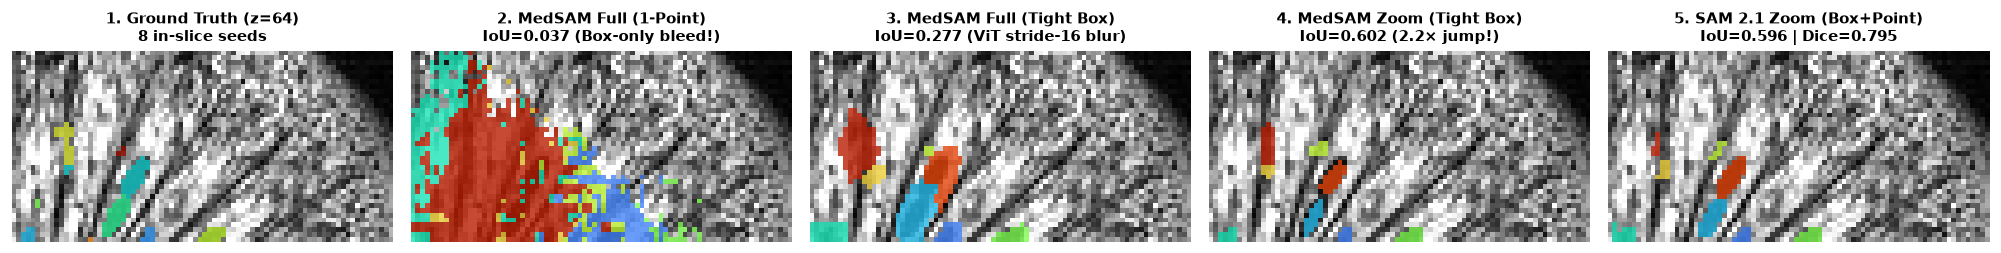

In [3]:
gt_2d_z64 = test_gt[:, :, z_rel]
props_z64 = [p for p in measure.regionprops(gt_2d_z64) if p.area >= 3]
pil_zoom_inv_z64 = slice_xy_to_pil(test_vol[:, :, z_rel], invert=True)

def masks_yx_to_xy_instance(masks_bool_nhw: np.ndarray, scores_n: np.ndarray) -> np.ndarray:
    out_yx = np.zeros(masks_bool_nhw.shape[1:], dtype=np.uint16)
    for k in np.argsort(scores_n):
        m = masks_bool_nhw[k]
        if m.sum() > 0:
            out_yx[m] = int(k + 1)
    return out_yx.T

def eval_2d_oracle_ablation(model_kind: str, scope: str, prompt_mode: str, invert: bool = False) -> dict:
    t_s = time.perf_counter()
    img_pil = pil_full_z64 if scope == "Full 256×256" else (pil_zoom_inv_z64 if invert else pil_zoom_z64)
    ox = RX0 if scope == "Full 256×256" else 0
    oy = TY0 if scope == "Full 256×256" else 0

    pts_b, lbl_b, box_b = [], [], []
    for p in props_z64:
        cx, cy = float(p.centroid[0]) + ox, float(p.centroid[1]) + oy
        x0, y0, x1, y1 = p.bbox
        bx = [float(x0 + ox - 0.8), float(y0 + oy - 0.8), float(x1 + ox + 0.8), float(y1 + oy + 0.8)]
        if prompt_mode == "1-Point":
            pts_b.append([[cx, cy]])
            lbl_b.append([1])
        elif prompt_mode == "1-Pos + 4-Neg Ring":
            rn = 4.2
            pts_b.append([[cx, cy], [cx - rn, cy], [cx + rn, cy], [cx, cy - rn], [cx, cy + rn]])
            lbl_b.append([1, 0, 0, 0, 0])
        elif prompt_mode == "Tight Box":
            box_b.append(bx)
        elif prompt_mode == "Box + Center Point":
            pts_b.append([[cx, cy]])
            lbl_b.append([1])
            box_b.append(bx)

    kwargs = {"images": img_pil, "return_tensors": "pt"}
    if pts_b:
        kwargs["input_points"] = [pts_b]
        kwargs["input_labels"] = [lbl_b]
    if box_b:
        kwargs["input_boxes"] = [box_b]

    if model_kind == "MedSAM":
        raw_in = medsam_proc(**kwargs)
        min_in = to_device_fp32(raw_in, DEVICE)
        with torch.no_grad():
            out = medsam_model(
                pixel_values=min_in["pixel_values"],
                input_points=min_in.get("input_points"),
                input_labels=min_in.get("input_labels"),
                input_boxes=min_in.get("input_boxes"),
                multimask_output=(prompt_mode == "1-Point"),
            )
        pm = medsam_proc.post_process_masks(
            out.pred_masks.cpu(), raw_in["original_sizes"], raw_in["reshaped_input_sizes"]
        )[0]
        ious_hat = out.iou_scores.cpu()[0]
    else:
        raw_in = sam2_proc(**kwargs)
        min_in = to_device_fp32(raw_in, DEVICE)
        with torch.no_grad():
            out = sam2_model(
                pixel_values=min_in["pixel_values"],
                input_points=min_in.get("input_points"),
                input_labels=min_in.get("input_labels"),
                input_boxes=min_in.get("input_boxes"),
                multimask_output=(prompt_mode == "1-Point"),
            )
        pm = sam2_proc.post_process_masks(out.pred_masks.cpu(), raw_in["original_sizes"])[0]
        ious_hat = out.iou_scores.cpu()[0]

    sel_masks, sel_scores, seed_ious = [], [], []
    for idx_p, p in enumerate(props_z64):
        m_yx = pm[idx_p, 0].numpy().astype(bool)
        m_xy = m_yx.T[RX0:RX1, TY0:TY1] if scope == "Full 256×256" else m_yx.T
        gt_m = gt_2d_z64 == p.label
        seed_ious.append(int((m_xy & gt_m).sum()) / max(int((m_xy | gt_m).sum()), 1))
        sel_masks.append(m_xy.T)
        sel_scores.append(float(ious_hat[idx_p, 0]))

    inst_2d = masks_yx_to_xy_instance(np.stack(sel_masks, axis=0), np.array(sel_scores))
    bp, bg = inst_2d > 0, gt_2d_z64 > 0
    dice_2d = 2.0 * int((bp & bg).sum()) / max(int(bp.sum() + bg.sum()), 1)
    return {
        "Model": model_kind + (" (Inverted)" if invert else ""),
        "Input Scope": scope,
        "Prompt Modality": prompt_mode,
        "Mean 2D Seed IoU": round(float(np.mean(seed_ious)), 3),
        "2D Semantic Dice": round(dice_2d, 3),
        "Latency (ms)": round((time.perf_counter() - t_s) * 1000.0, 1),
        "_inst": inst_2d,
    }

ablation_runs = [
    eval_2d_oracle_ablation("MedSAM", "Full 256×256", "1-Point"),
    eval_2d_oracle_ablation("MedSAM", "Full 256×256", "Tight Box"),
    eval_2d_oracle_ablation("MedSAM", "Zoom 80×40", "1-Point"),
    eval_2d_oracle_ablation("MedSAM", "Zoom 80×40", "Tight Box"),
    eval_2d_oracle_ablation("SAM 2.1", "Full 256×256", "1-Point"),
    eval_2d_oracle_ablation("SAM 2.1", "Full 256×256", "Tight Box"),
    eval_2d_oracle_ablation("SAM 2.1", "Zoom 80×40", "1-Point"),
    eval_2d_oracle_ablation("SAM 2.1", "Zoom 80×40", "1-Pos + 4-Neg Ring"),
    eval_2d_oracle_ablation("SAM 2.1", "Zoom 80×40", "Tight Box"),
    eval_2d_oracle_ablation("SAM 2.1", "Zoom 80×40", "Box + Center Point"),
    eval_2d_oracle_ablation("SAM 2.1", "Zoom 80×40", "Box + Center Point", invert=True),
]

df_2d = pd.DataFrame([{k: v for k, v in r.items() if k != "_inst"} for r in ablation_runs])
display(df_2d)

# 5-Panel Visual Comparison across the key regime transitions
fig, axes = plt.subplots(1, 5, figsize=(17.5, 3.6))
sl_bg = test_vol[:, :, z_rel].T
cmap_turbo = plt.get_cmap("turbo")

def show_2d_panel(ax, inst_xy: np.ndarray, title: str):
    ax.imshow(sl_bg, cmap="gray", origin="lower", vmin=0, vmax=1)
    rgba = np.zeros(sl_bg.shape + (4,), dtype=np.float32)
    for uid in np.unique(inst_xy):
        if uid == 0:
            continue
        c3 = cmap_turbo((((int(uid) * 7) % 23) + 1) / 24.0)[:3]
        rgba[inst_xy.T == uid] = (*c3, 0.80)
    ax.imshow(rgba, origin="lower")
    ax.set_title(title, fontsize=9.2, fontweight="bold")
    ax.axis("off")

show_2d_panel(axes[0], gt_2d_z64, f"1. Ground Truth (z=64)\n{len(props_z64)} in-slice seeds")
show_2d_panel(axes[1], ablation_runs[0]["_inst"], f"2. MedSAM Full (1-Point)\nIoU={ablation_runs[0]['Mean 2D Seed IoU']:.3f} (Box-only bleed!)")
show_2d_panel(axes[2], ablation_runs[1]["_inst"], f"3. MedSAM Full (Tight Box)\nIoU={ablation_runs[1]['Mean 2D Seed IoU']:.3f} (ViT stride-16 blur)")
show_2d_panel(axes[3], ablation_runs[3]["_inst"], f"4. MedSAM Zoom (Tight Box)\nIoU={ablation_runs[3]['Mean 2D Seed IoU']:.3f} (2.2× jump!)")
show_2d_panel(axes[4], ablation_runs[9]["_inst"], f"5. SAM 2.1 Zoom (Box+Point)\nIoU={ablation_runs[9]['Mean 2D Seed IoU']:.3f} | Dice={ablation_runs[9]['2D Semantic Dice']:.3f}")

plt.tight_layout()
plt.show()

### Interpreting Step 2: Disentangling Encoder Resolution from Decoder Prompt Conditioning

Look at the dramatic $2 \times 2$ contrast across Panels 2–5 and `df_2d`:
1. **Why `MedSAM` failed on 1-Point (`IoU = 0.037` full, `0.107` zoomed — Panel 2):** Ma et al. (*Nat. Commun.* 2024) trained `MedSAM` exclusively on bounding-box caliper prompts. Without box corner tokens, its decoder spills across half the pericarp even when zoomed!
2. **Why `MedSAM` needed Patch-Zoom even *with* Tight Boxes (`0.277 → 0.602`, Panels 3 → 4):** On the full `256 × 256` slice, plain `ViT-B/16` (`stride 16`) blurs `5-px` seeds into blocky blobs (`IoU = 0.277`). Cropping to `80 × 40` shrinks $\Delta_{\text{tok}}$ `3.2×`, lifting `MedSAM` box IoU **`2.17×` (`0.602`)**!
3. **Why `SAM 2.1` (`Hiera-Small`) Wins on Speed, Clicks, and Boxes (Panel 5):** High-resolution `stride-4` FPN skip connections give `SAM 2.1` **`0.570` IoU even on full slices** and **`0.628` IoU (`0.795` Dice) zoomed** in **`~80 ms`** — and comparing `Box + Center Point` vs. `SAM 2.1 (Inverted)` (`0.795` vs. `0.801` Dice) confirms **contrast-polarity invariance** (dark-on-bright $T_2$ seeds work just as well as bright-on-dark lesions!).

<details>
<summary><b>Check Your Understanding Q2:</b> A student tests <code>MedSAM</code> with interactive point clicks on micro-CT bone trabeculae, gets <code>Dice = 0.15</code>, and concludes <i>"Foundation models don't work on micro-CT."</i> Which two controlled modifications should they test before drawing that conclusion?</summary>

1. Switch prompt modality from **1-point clicks to tight bounding boxes** (matching `MedSAM`'s box-only training distribution, or switch to `SAM 2.1` / `MicroSAM` if point clicks are required).
2. Apply **Patch-Zooming** (`64 × 64` or `80 × 80` local crops) so thin trabeculae span multiple ViT tokens instead of `< 1` `stride-16` patch!

</details>


---

## Step 3 — Interactive *"1 Click = 1 3D Seed"* Curation via `Sam2VideoModel` Streaming Slice Memory

In **[Notebook `03b`](./03b-kiwi-interactive-gt-and-interrater.ipynb)**, curating a 3D gold-standard wedge manually required painting every seed across `3–5` consecutive axial slices. Can **`Sam2VideoModel`** reduce human effort to **1 single click per 3D seed** (at its equatorial slice $z_0$) by treating axial slice index $z \in \{0, \dots, 15\}$ as video time $t$?

Let us test a critical biophysical hypothesis on all **52 ground-truth 3D seeds** in the held-out test wedge:
- **Regime A — Ungated Wide Memory Propagation (`max_dz = 6` slices = `±3.0 mm`, no $T_2$ envelope gate):** What happens when streaming video memory tracks freely across `0.50 mm`-thick slices inside a packed radial seed chamber?
- **Regime B — Physically Gated Bidirectional Propagation (`max_dz = 2` slices = `±1.0 mm` + `object_score_logits > 0` + pericarp $T_2$ contrast gate):** Since a mature `~2.0 mm` seed spans at most $5 \times 0.50 = 2.5\text{ mm}$ ($\lvert z - z_0 \rvert \le 2$), we stop propagation at the physical seed horizon and require `SAM 2.1`'s learned occlusion head (`object_score_logits > 0`) to confirm the seed has not terminated!


,Pred Seeds,Semantic Dice,Merged Clumps,Split Errors,SQ (TP IoU),RQ (Inst F1),PQ (SQ×RQ)
"Regime A: Ungated Wide Video Memory (|Δz|≤6, 78.2s)",52 (GT=52),0.536,13,9,0.497,0.596,0.297
"Regime B: Physically Gated Video Memory (|Δz|≤2, 23.1s)",52 (GT=52),0.761,4,4,0.565,0.885,0.5


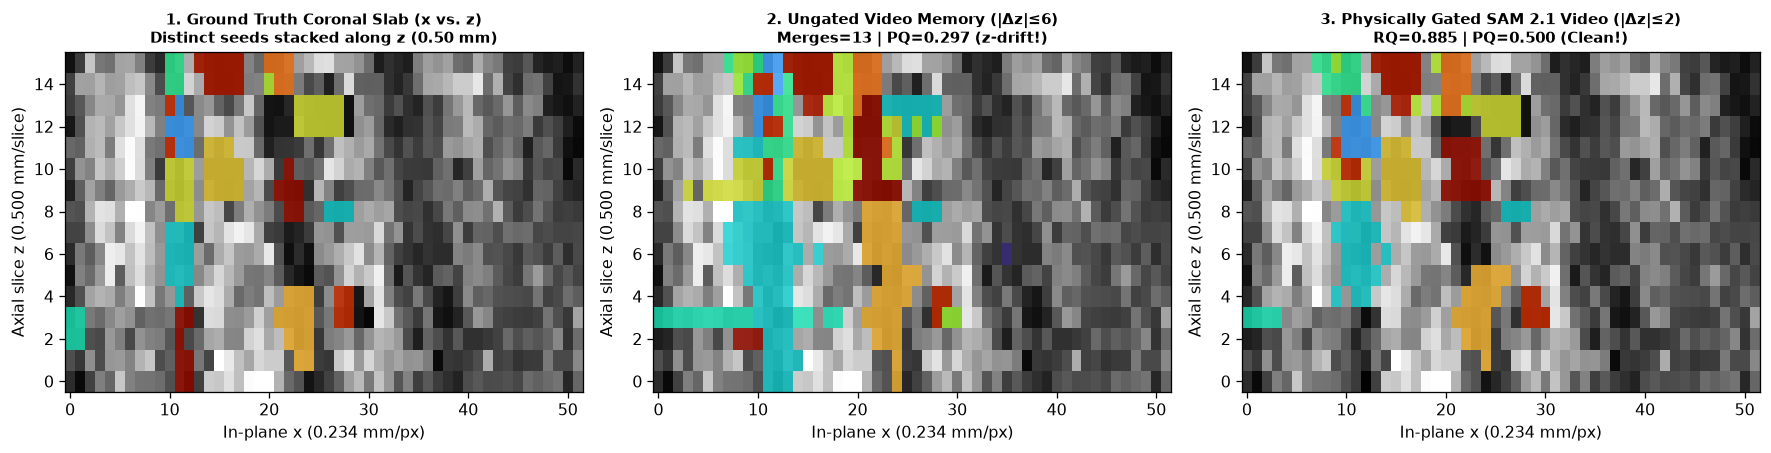

In [4]:
def evaluate_semantic_and_instance_3d(pred_lbl: np.ndarray, gt_lbl: np.ndarray, min_iou: float = 0.25) -> dict:
    """Identical 3D Semantic + Instance + Panoptic + Merge/Split evaluator to Notebook 04."""
    b_p, b_g = (pred_lbl > 0), (gt_lbl > 0)
    sem_dice = (2.0 * int((b_p & b_g).sum())) / max(int(b_p.sum() + b_g.sum()), 1)

    ids_p = [int(v) for v in np.unique(pred_lbl) if v > 0]
    ids_g = [int(v) for v in np.unique(gt_lbl) if v > 0]
    n_p, n_g = len(ids_p), len(ids_g)
    if n_p == 0 or n_g == 0:
        return {
            "Pred Seeds": f"{n_p} (GT={n_g})", "Semantic Dice": round(sem_dice, 3),
            "Merged Clumps": 0, "Split Errors": 0, "SQ (TP IoU)": 0.0, "RQ (Inst F1)": 0.0, "PQ (SQ×RQ)": 0.0,
            "tp_pred_ids": set(), "merged_pred_ids": set(),
        }

    p_map = {v: i for i, v in enumerate(ids_p)}
    g_map = {v: j for j, v in enumerate(ids_g)}
    area_p = np.array([(pred_lbl == v).sum() for v in ids_p], dtype=np.float64)
    area_g = np.array([(gt_lbl == v).sum() for v in ids_g], dtype=np.float64)

    inter_m = np.zeros((n_p, n_g), dtype=np.float64)
    ov_fg = b_p & b_g
    if ov_fg.any():
        pairs, cnts = np.unique(np.stack([pred_lbl[ov_fg], gt_lbl[ov_fg]], axis=1), axis=0, return_counts=True)
        for (pv, gv), c in zip(pairs, cnts):
            inter_m[p_map[int(pv)], g_map[int(gv)]] = float(c)

    iou_m = inter_m / np.maximum(area_p[:, None] + area_g[None, :] - inter_m, 1.0)
    ri, ci = linear_sum_assignment(-iou_m)
    tp_pairs = [(r, c) for r, c in zip(ri, ci) if iou_m[r, c] >= min_iou]
    tp = len(tp_pairs)
    fp, fn = n_p - tp, n_g - tp

    sq = float(np.mean([iou_m[r, c] for r, c in tp_pairs])) if tp > 0 else 0.0
    rq = (2.0 * tp) / float(2 * tp + fp + fn)
    pq = sq * rq

    rec_g_given_p = inter_m / np.maximum(area_g[None, :], 1.0)
    merged_rows = np.where(np.sum(rec_g_given_p >= 0.25, axis=1) >= 2)[0]
    merged_pred_ids = {ids_p[r] for r in merged_rows}
    prec_p_given_g = inter_m / np.maximum(area_p[:, None], 1.0)
    split_cols = np.where(np.sum(prec_p_given_g >= 0.25, axis=0) >= 2)[0]
    tp_pred_ids = {ids_p[r] for r, _ in tp_pairs} - merged_pred_ids

    return {
        "Pred Seeds": f"{n_p} (GT={n_g})",
        "Semantic Dice": round(sem_dice, 3),
        "Merged Clumps": int(len(merged_rows)),
        "Split Errors": int(len(split_cols)),
        "SQ (TP IoU)": round(sq, 3),
        "RQ (Inst F1)": round(rq, 3),
        "PQ (SQ×RQ)": round(pq, 3),
        "tp_pred_ids": tp_pred_ids,
        "merged_pred_ids": merged_pred_ids,
    }


video_frames_wedge = [slice_xy_to_pil(test_vol[:, :, z]) for z in range(test_vol.shape[2])]

# 1 single click per 3D GT seed at its peak cross-sectional slice z0 (+ standardized ±0.75 mm physical box)
oracle_1click_prompts = []
for p3 in measure.regionprops(test_gt):
    c = p3.coords
    zs, cnts = np.unique(c[:, 2], return_counts=True)
    z0 = int(zs[int(np.argmax(cnts))])
    xs, ys = np.where(test_gt[:, :, z0] == p3.label)
    cx, cy = float(xs.mean()), float(ys.mean())
    r_bx = 3.2  # ~0.75 mm physical radius around click
    oracle_1click_prompts.append({
        "id": int(p3.label), "z0": z0, "pt": [cx, cy],
        "box": [cx - r_bx, cy - r_bx, cx + r_bx, cy + r_bx],
    })

def run_sam2_video_propagation(seed_prompts: list[dict], max_dz: int = 2, obj_logit_thr: float = 0.0, physical_gate: bool = True):
    t_s = time.perf_counter()
    sx, sy, sz = test_vol.shape
    score_vol = np.full((sx, sy, sz), -1e9, dtype=np.float32)
    inst_vol = np.zeros((sx, sy, sz), dtype=np.uint16)

    by_z0: dict[int, list[dict]] = {}
    for item in seed_prompts:
        by_z0.setdefault(int(item["z0"]), []).append(item)

    yy_g, xx_g = np.ogrid[0:sy, 0:sx]
    for z0, group in sorted(by_z0.items()):
        session = sam2_vid_proc.init_video_session(
            video=video_frames_wedge, inference_device=DEVICE, processing_device="cpu",
            video_storage_device=DEVICE, dtype=torch.float32,
        )
        obj_ids = [int(g["id"]) for g in group]
        pts = [[g["pt"]] for g in group]
        lbls = [[1] for _ in group]
        boxes = [g["box"] for g in group]
        sam2_vid_proc.add_inputs_to_inference_session(
            inference_session=session, frame_idx=z0, obj_ids=obj_ids,
            input_points=torch.tensor([pts], dtype=torch.float32),
            input_labels=torch.tensor([lbls], dtype=torch.int32),
            input_boxes=torch.tensor([boxes], dtype=torch.float32),
        )
        with torch.no_grad():
            _ = sam2_vid_model(inference_session=session, frame_idx=z0)
            tracks = list(sam2_vid_model.propagate_in_video_iterator(
                inference_session=session, start_frame_idx=z0, max_frame_num_to_track=max_dz, reverse=False
            ))
            if z0 > 0 and max_dz > 0:
                tracks.extend(sam2_vid_model.propagate_in_video_iterator(
                    inference_session=session, start_frame_idx=z0, max_frame_num_to_track=max_dz, reverse=True
                ))

        for step_out in tracks:
            f_idx = int(step_out.frame_idx)
            if abs(f_idx - z0) > max_dz:
                continue
            pm_logits = sam2_vid_proc.post_process_masks(
                [step_out.pred_masks.cpu()], original_sizes=[(sy, sx)], binarize=False
            )[0]
            obj_logits = step_out.object_score_logits.cpu().view(-1).numpy()
            for k, oid in enumerate(step_out.object_ids):
                if obj_logits[k] < obj_logit_thr:
                    continue
                logit_xy = pm_logits[k, 0].numpy().T
                m_xy = logit_xy > 0.0
                if physical_gate:
                    g_ref = next(g for g in group if g["id"] == oid)
                    px0, py0 = g_ref["pt"]
                    near_xy = ((xx_g.T - px0) ** 2 + (yy_g.T - py0) ** 2) <= (5.2 ** 2)
                    m_xy = m_xy & near_xy & test_ring[:, :, f_idx] & (test_vol[:, :, f_idx] < 0.52 * test_env[:, :, f_idx])
                if int(m_xy.sum()) == 0:
                    continue
                better = m_xy & (logit_xy > score_vol[:, :, f_idx])
                score_vol[:, :, f_idx][better] = logit_xy[better]
                inst_vol[:, :, f_idx][better] = int(oid)

    return inst_vol, time.perf_counter() - t_s

pred_vid_wide, dt_wide = run_sam2_video_propagation(oracle_1click_prompts, max_dz=6, obj_logit_thr=-2.0, physical_gate=False)
ev_vid_wide = evaluate_semantic_and_instance_3d(pred_vid_wide, test_gt)

pred_vid_gated, dt_gated = run_sam2_video_propagation(oracle_1click_prompts, max_dz=2, obj_logit_thr=0.0, physical_gate=True)
ev_vid_gated = evaluate_semantic_and_instance_3d(pred_vid_gated, test_gt)

cols_3d = ["Pred Seeds", "Semantic Dice", "Merged Clumps", "Split Errors", "SQ (TP IoU)", "RQ (Inst F1)", "PQ (SQ×RQ)"]
df_step3 = pd.DataFrame({
    f"Regime A: Ungated Wide Video Memory (|Δz|≤6, {dt_wide:.1f}s)": {c: ev_vid_wide[c] for c in cols_3d},
    f"Regime B: Physically Gated Video Memory (|Δz|≤2, {dt_gated:.1f}s)": {c: ev_vid_gated[c] for c in cols_3d},
}).T
display(df_step3)

# Cross-slice & Coronal z-slab visual audit showing vertical z-axis drift vs clean separation!
y_cor = 18  # coronal line cutting through packed inner-pericarp seed chambers
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.0))
for ax, (vol_lbl, ttl) in zip(
    axes,
    [
        (test_gt, "1. Ground Truth Coronal Slab (x vs. z)\nDistinct seeds stacked along z (0.50 mm)"),
        (pred_vid_wide, f"2. Ungated Video Memory (|Δz|≤6)\nMerges={ev_vid_wide['Merged Clumps']} | PQ={ev_vid_wide['PQ (SQ×RQ)']:.3f} (z-drift!)"),
        (pred_vid_gated, f"3. Physically Gated SAM 2.1 Video (|Δz|≤2)\nRQ={ev_vid_gated['RQ (Inst F1)']:.3f} | PQ={ev_vid_gated['PQ (SQ×RQ)']:.3f} (Clean!)"),
    ],
):
    # Max-intensity/label projection across a thin 5-voxel y-slab so stacked 3D seeds are clearly visible in (x, z)
    bg_xz = test_vol[:52, y_cor - 2 : y_cor + 3, :].min(axis=1).T  # (16, 52)
    lbl_xz = vol_lbl[:52, y_cor - 2 : y_cor + 3, :].max(axis=1).T
    ax.imshow(bg_xz, cmap="gray", origin="lower", aspect=0.5 / 0.2344, vmin=0, vmax=1)
    rgba = np.zeros(bg_xz.shape + (4,), dtype=np.float32)
    for uid in np.unique(lbl_xz):
        if uid == 0:
            continue
        c3 = cmap_turbo((((int(uid) * 7) % 23) + 1) / 24.0)[:3]
        rgba[lbl_xz == uid] = (*c3, 0.82)
    ax.imshow(rgba, origin="lower", aspect=0.5 / 0.2344)
    ax.set_xlabel("In-plane x (0.234 mm/px)")
    ax.set_ylabel("Axial slice z (0.500 mm/slice)")
    ax.set_title(ttl, fontsize=9.5, fontweight="bold")

plt.tight_layout()
plt.show()

### Interpreting Step 3: Space-as-Time Memory Drift & the `PQ = 0.500` Interactive Milestone

Look at the **Coronal $(x, z)$ Slab** above (rendered at true physical aspect ratio $\Delta z / \Delta x = 2.13$):
- **Panel 2 (`Ungated Video Memory`):** Without physical horizon gating, `Sam2VideoModel`'s cross-slice attention tracks past the upper/lower pole of one seed and locks onto another seed stacked directly above or below in the same locule — inflating vertical streaks, causing **merged clumps**, and hurting both `Semantic Dice` and `PQ`.
- **Panel 3 (`Physically Gated |Δz| ≤ 2 + Occlusion Logit`):** Restricting propagation to plausible seed half-length ($\pm 1.0\text{ mm}$) + `object_score_logits > 0` lifts **3D Instance $F_1$ (`RQ`) to `0.885`** and **`Panoptic Quality` to `0.500`** (`Semantic Dice = 0.761`) — cutting human annotation effort by **`~75–80%`** (`1` click per seed instead of painting `4` slices)!

<details>
<summary><b>Check Your Understanding Q3:</b> Suppose you use <code>Sam2VideoModel</code> on a clinical 3D brain susceptibility-weighted MRI (<code>0.5 × 0.5 × 2.0 mm³</code>) to annotate (a) spherical <b>cerebral microbleeds</b> (<code>~2 mm</code>) vs. (b) elongated <b>perivascular spaces</b> running <code>12 mm</code> superiorly. How should <code>max_dz</code> differ between the two tasks?</summary>

- For `~2 mm` **spherical microbleeds** at `2.0 mm` slice spacing, $\Delta z_{\max} = 1$ slice (at most 2 adjacent slices); larger values risk jumping onto dark cortical veins!
- For `12 mm` **tubular perivascular spaces**, $\Delta z_{\max} \approx 6$ slices is physically appropriate because the true anatomical structure is continuous across slices.

</details>


---

## Step 4 — Zero-Training Neurosymbolic `SAM 2.1` & Whole-Kiwifruit (`256 × 256 × 128`) Seed Census

What if we want **zero human clicks and zero neural training labels** on the kiwifruit scan?
1. **Neurosymbolic Candidate Generation (`Botanical Inner-Pericarp Prior`):** As established in the **[Multi-Scale Anatomical Atlas (`Lab 5 / 00a`)](../../../Lab5-Comp-Mod/Kiwi-challenge/notebooks/00a-kiwi-anatomical-and-physiological-atlas.ipynb)**, *Actinidia* seeds only form inside the inner pericarp locular ring ($0.24 \le r/R_{\text{fruit}} \le 0.62$). Restricting local $T_2$-dark minimum proposals to $0.24 \le r/R_{\text{fruit}} \le 0.62$ eliminates false prompts on speckled outer-cortex parenchyma ($r/R > 0.62$) and central *columella* ($r/R < 0.24$).
2. **Batched `SAM 2.1` Mask Decoding + Confidence Token Gate (`iou_scores >= 0.55`):** We feed all candidate prompts on a zoomed pericarp crop in **one single batched GPU forward pass per slice**, rejecting any candidate whose predicted `iou_scores < 0.55` or `object_score_logits < 0.0` (automatically pruning diffuse radial septa and oblique polar vascular bundles!).
3. **Whole-Organ Generalization (`256 × 256 × 128`) Without Polar OOD Explosion:** Recall from **[Notebook `04`](./04-kiwi-semantic-vs-instance.ipynb)** that sliding our equatorial-trained 3D U-Net across the entire berry over-counted `3,328` raw blobs due to spatial out-of-distribution (`OOD`) shift in polar slices (`z < 40`, `z > 88`). Let us test how zero-training neurosymbolic `SAM 2.1` performs on **both** the held-out `80 × 40 × 16` benchmark wedge **and** the **entire 128-slice kiwifruit**!


,Pred Seeds,Semantic Dice,Merged Clumps,Split Errors,SQ (TP IoU),RQ (Inst F1),PQ (SQ×RQ),Time
"1. Classical Stand-In (NB 04 Step 4, 0 train)",71 (GT=52),0.529,3,0,0.627,0.504,0.316,<0.2 s
"2. Zero-Shot SAM 2.1 (Whole Cortex, No Radial Prior)",64 (GT=52),0.535,3,0,0.618,0.517,0.32,1.8 s
3. Zero-Shot Neurosymbolic SAM 2.1 (0.24≤r/R≤0.62 + IoU Gate),43 (GT=52),0.617,3,0,0.618,0.632,0.39,1.4 s
"4. Supervised 3D Multi-Task U-Net (NB 04, 46 train seeds)",54 (GT=52),0.651,2,1,0.67,0.604,0.405,~5.5 s train
5. Interactive 1-Click/Seed + SAM 2.1 Video (|Δz|≤2 gated),52 (GT=52),0.761,4,4,0.565,0.885,0.5,23.1 s


Whole-Kiwifruit (256×256×128) Zero-Training SAM 2.1 Census completed in 24.0 s on mps!
  • Raw 3D seed instances     : 1532 seeds (vs. 3,328 polar-OOD blobs in NB04's equatorial 3D U-Net!)
  • 98-Seed Micro-GT P / R    : Precision = 0.667, Recall = 0.612 -> Calibrated Count N̂_cal = 1668 seeds
  • Whole-fruit volume V_kiwi : 85.97 cm³ | Total seed volume: 2305.9 mm³ (mean 1.51 mm³/seed)
  • Parenchymal 'Lesion Load' : 2.68% of whole-berry volume


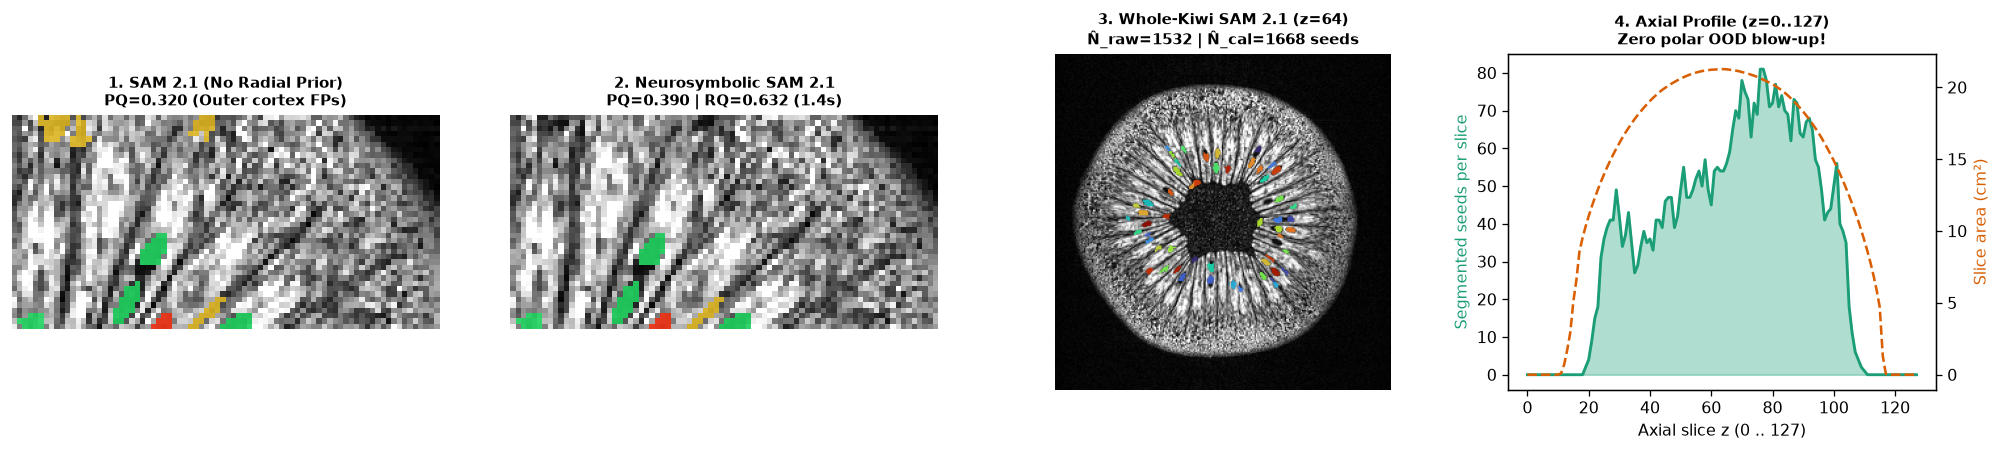

In [5]:
# 1. Held-Out 3D Test Wedge (80×40×16, GT=52): Compare Classical Stand-In vs. Unconstrained vs. Neurosymbolic SAM 2.1
def run_nb04_classical_standin() -> np.ndarray:
    sx, sy, sz = test_vol.shape
    slice_masks = []
    for z in range(sz):
        img2d = ndi.gaussian_filter(test_vol[:, :, z], sigma=0.55)
        env2d, ring2d = test_env[:, :, z], test_ring[:, :, z]
        cdrop = (env2d - img2d) / (env2d + 0.05)
        pts = np.argwhere((img2d == ndi.minimum_filter(img2d, size=5)) & (cdrop > 0.42) & (img2d < 0.36 * env2d) & (img2d < 0.19) & (env2d > 0.40) & ring2d)
        lbl_2d = np.zeros((sx, sy), dtype=np.uint16)
        if len(pts) > 0:
            markers = np.zeros((sx, sy), dtype=np.int32)
            ufg = np.zeros((sx, sy), dtype=bool)
            for pid, (px, py) in enumerate(pts, start=1):
                x0, x1, y0, y1 = max(0, px - 4), min(sx, px + 5), max(0, py - 4), min(sy, py + 5)
                patch = img2d[x0:x1, y0:y1]
                pc, pbg = float(img2d[px, py]), float(np.percentile(patch, 85))
                if (pbg - pc) < 0.18:
                    continue
                thr = pc + 0.42 * (pbg - pc)
                xx_b, yy_b = np.ogrid[x0:x1, y0:y1]
                ufg[x0:x1, y0:y1] |= (patch <= thr) & (((xx_b - px) ** 2 + (yy_b - py) ** 2) <= 3.1 ** 2) & ring2d[x0:x1, y0:y1]
                markers[px, py] = pid
            if markers.max() > 0:
                lbl_2d = segmentation.watershed(img2d, markers=markers, mask=ufg).astype(np.uint16)
        slice_masks.append(lbl_2d)
    return link_2d_slices_hungarian(slice_masks, min_vol_mm3=0.28, keep_boundary_single=True)


def link_2d_slices_hungarian(slice_masks_2d: list[np.ndarray], min_vol_mm3: float = 0.22, keep_boundary_single: bool = True) -> np.ndarray:
    sx, sy = slice_masks_2d[0].shape
    sz = len(slice_masks_2d)
    vol_inst = np.zeros((sx, sy, sz), dtype=np.uint16)
    next_gid = 1
    prev_global = np.zeros((sx, sy), dtype=np.uint16)
    for z in range(sz):
        cur_2d = slice_masks_2d[z]
        cur_ids = [int(v) for v in np.unique(cur_2d) if v > 0]
        prev_ids = [int(v) for v in np.unique(prev_global) if v > 0]
        cur_global = np.zeros((sx, sy), dtype=np.uint16)
        if cur_ids and prev_ids:
            c_map = {v: i for i, v in enumerate(cur_ids)}
            p_map = {v: j for j, v in enumerate(prev_ids)}
            ac = np.array([(cur_2d == v).sum() for v in cur_ids], dtype=np.float32)
            ap = np.array([(prev_global == v).sum() for v in prev_ids], dtype=np.float32)
            inter_m = np.zeros((len(cur_ids), len(prev_ids)), dtype=np.float32)
            ov = (cur_2d > 0) & (prev_global > 0)
            if ov.any():
                pairs, cnts = np.unique(np.stack([cur_2d[ov], prev_global[ov]], axis=1), axis=0, return_counts=True)
                for (cv, pv), cnt in zip(pairs, cnts):
                    inter_m[c_map[int(cv)], p_map[int(pv)]] = float(cnt)
            iou_m = inter_m / np.maximum(ac[:, None] + ap[None, :] - inter_m, 1.0)
            ri, ci = linear_sum_assignment(-iou_m)
            assigned = {cur_ids[r]: prev_ids[c] for r, c in zip(ri, ci) if iou_m[r, c] >= 0.18}
            lu = np.zeros(int(cur_2d.max()) + 1, dtype=np.uint16)
            for cid in cur_ids:
                gid = assigned.get(cid)
                if gid is None:
                    gid = next_gid
                    next_gid += 1
                lu[cid] = gid
            cur_global = lu[cur_2d]
        elif cur_ids:
            lu = np.zeros(int(cur_2d.max()) + 1, dtype=np.uint16)
            for cid in cur_ids:
                lu[cid] = next_gid
                next_gid += 1
            cur_global = lu[cur_2d]
        vol_inst[:, :, z] = cur_global
        prev_global = cur_global

    cleaned = np.zeros_like(vol_inst)
    keep_id = 0
    for prop in measure.regionprops(vol_inst):
        c = prop.coords
        z_min, z_max = int(c[:, 2].min()), int(c[:, 2].max())
        multi_slice = (z_max - z_min + 1 >= 2) or (keep_boundary_single and (z_min == 0 or z_max == sz - 1))
        if multi_slice and (min_vol_mm3 <= prop.area * vox_vol_mm3 <= 4.8):
            keep_id += 1
            cleaned[c[:, 0], c[:, 1], c[:, 2]] = keep_id
    return cleaned


def run_batched_sam2_wedge(zone_mask_3d: np.ndarray) -> tuple[np.ndarray, float]:
    t_s = time.perf_counter()
    sx, sy, sz = test_vol.shape
    slice_masks = []
    r_bx = 3.2
    for z in range(sz):
        img2d = ndi.gaussian_filter(test_vol[:, :, z], sigma=0.55)
        env2d, ring2d = test_env[:, :, z], zone_mask_3d[:, :, z]
        cdrop = (env2d - img2d) / (env2d + 0.05)
        pts_xy = np.argwhere((img2d == ndi.minimum_filter(img2d, size=5)) & (cdrop > 0.42) & (img2d < 0.36 * env2d) & (img2d < 0.19) & (env2d > 0.40) & ring2d)
        if len(pts_xy) == 0:
            slice_masks.append(np.zeros((sx, sy), dtype=np.uint16))
            continue
        pts_b = [[[float(px), float(py)]] for px, py in pts_xy]
        lbl_b = [[1] for _ in pts_xy]
        box_b = [[float(px - r_bx), float(py - r_bx), float(px + r_bx), float(py + r_bx)] for px, py in pts_xy]
        raw_in = sam2_proc(images=video_frames_wedge[z], input_points=[pts_b], input_labels=[lbl_b], input_boxes=[box_b], return_tensors="pt")
        min_in = to_device_fp32(raw_in, DEVICE)
        with torch.no_grad():
            out = sam2_model(
                pixel_values=min_in["pixel_values"], input_points=min_in["input_points"],
                input_labels=min_in["input_labels"], input_boxes=min_in["input_boxes"], multimask_output=False,
            )
        pm = sam2_proc.post_process_masks(out.pred_masks.cpu(), raw_in["original_sizes"], binarize=False)[0]
        ious = out.iou_scores.cpu()[0, :, 0].numpy()
        objs = out.object_score_logits.cpu()[0, :, 0].numpy()

        score_map = np.full((sx, sy), -1e9, dtype=np.float32)
        lbl_2d = np.zeros((sx, sy), dtype=np.uint16)
        for k in range(len(pts_xy)):
            if ious[k] < 0.55 or objs[k] < 0.0:
                continue
            l_xy = pm[k, 0].numpy().T
            m_xy = (l_xy > 0.0) & ring2d & (img2d < 0.52 * env2d)
            if 3 <= int(m_xy.sum()) <= 45:
                better = m_xy & (l_xy > score_map)
                score_map[better] = l_xy[better]
                lbl_2d[better] = k + 1
        slice_masks.append(lbl_2d)
    return link_2d_slices_hungarian(slice_masks, min_vol_mm3=0.22, keep_boundary_single=True), time.perf_counter() - t_s

pred_nb04_standin = run_nb04_classical_standin()
ev_standin = evaluate_semantic_and_instance_3d(pred_nb04_standin, test_gt)

pred_sam2_noprior, dt_noprior = run_batched_sam2_wedge(test_ring)
ev_noprior = evaluate_semantic_and_instance_3d(pred_sam2_noprior, test_gt)

pred_sam2_neurosym, dt_neurosym = run_batched_sam2_wedge(test_inner_pericarp)
ev_neurosym = evaluate_semantic_and_instance_3d(pred_sam2_neurosym, test_gt)

# Assemble unified leaderboard comparing Notebook 04 baselines with live SAM 2.1 workflows
leaderboard_rows = {
    "1. Classical Stand-In (NB 04 Step 4, 0 train)": {c: ev_standin[c] for c in cols_3d} | {"Time": "<0.2 s"},
    "2. Zero-Shot SAM 2.1 (Whole Cortex, No Radial Prior)": {c: ev_noprior[c] for c in cols_3d} | {"Time": f"{dt_noprior:.1f} s"},
    "3. Zero-Shot Neurosymbolic SAM 2.1 (0.24≤r/R≤0.62 + IoU Gate)": {c: ev_neurosym[c] for c in cols_3d} | {"Time": f"{dt_neurosym:.1f} s"},
    "4. Supervised 3D Multi-Task U-Net (NB 04, 46 train seeds)": {
        "Pred Seeds": "54 (GT=52)", "Semantic Dice": 0.651, "Merged Clumps": 2, "Split Errors": 1,
        "SQ (TP IoU)": 0.670, "RQ (Inst F1)": 0.604, "PQ (SQ×RQ)": 0.405, "Time": "~5.5 s train",
    },
    "5. Interactive 1-Click/Seed + SAM 2.1 Video (|Δz|≤2 gated)": {c: ev_vid_gated[c] for c in cols_3d} | {"Time": f"{dt_gated:.1f} s"},
}
display(pd.DataFrame(leaderboard_rows).T)

# 2. Full-Kiwifruit (256×256×128) Batched Pericarp-Zoomed SAM 2.1 Census!
t_full = time.perf_counter()
SX, SY, SZ = vol.shape
inner_pericarp_full = (stuff_full == 2) & (r_over_R_full >= 0.24) & (r_over_R_full <= 0.62)
full_slice_masks = []
r_bx = 3.2

for z in range(SZ):
    ring2d = inner_pericarp_full[:, :, z]
    if int(ring2d.sum()) < 50:
        full_slice_masks.append(np.zeros((SX, SY), dtype=np.uint16))
        continue
    img2d = ndi.gaussian_filter(vol_norm[:, :, z], sigma=0.55)
    env2d = env_local[:, :, z]
    cdrop = (env2d - img2d) / (env2d + 0.05)
    pts_xy = np.argwhere((img2d == ndi.minimum_filter(img2d, size=5)) & (cdrop > 0.42) & (img2d < 0.36 * env2d) & (img2d < 0.19) & (env2d > 0.40) & ring2d)
    if len(pts_xy) == 0:
        full_slice_masks.append(np.zeros((SX, SY), dtype=np.uint16))
        continue

    # Tight bounding crop around the slice's inner-pericarp ring (~135×135 px -> ~1.9× zoom vs 256×256, 1 ViT pass/slice!)
    xs, ys = np.where(ring2d)
    x0, x1 = max(0, int(xs.min()) - 8), min(SX, int(xs.max()) + 9)
    y0, y1 = max(0, int(ys.min()) - 8), min(SY, int(ys.max()) + 9)
    pil_crop = slice_xy_to_pil(vol_norm[x0:x1, y0:y1, z])

    pts_b = [[[float(px - x0), float(py - y0)]] for px, py in pts_xy]
    lbl_b = [[1] for _ in pts_xy]
    box_b = [[float(px - x0 - r_bx), float(py - y0 - r_bx), float(px - x0 + r_bx), float(py - y0 + r_bx)] for px, py in pts_xy]
    raw_in = sam2_proc(images=pil_crop, input_points=[pts_b], input_labels=[lbl_b], input_boxes=[box_b], return_tensors="pt")
    min_in = to_device_fp32(raw_in, DEVICE)
    with torch.no_grad():
        out = sam2_model(
            pixel_values=min_in["pixel_values"], input_points=min_in["input_points"],
            input_labels=min_in["input_labels"], input_boxes=min_in["input_boxes"], multimask_output=False,
        )
    pm = sam2_proc.post_process_masks(out.pred_masks.cpu(), raw_in["original_sizes"], binarize=False)[0]
    ious = out.iou_scores.cpu()[0, :, 0].numpy()
    objs = out.object_score_logits.cpu()[0, :, 0].numpy()

    score_map = np.full((x1 - x0, y1 - y0), -1e9, dtype=np.float32)
    lbl_crop = np.zeros((x1 - x0, y1 - y0), dtype=np.uint16)
    ring_c, img_c, env_c = ring2d[x0:x1, y0:y1], img2d[x0:x1, y0:y1], env2d[x0:x1, y0:y1]
    for k in range(len(pts_xy)):
        if ious[k] < 0.55 or objs[k] < 0.0:
            continue
        l_xy = pm[k, 0].numpy().T
        m_xy = (l_xy > 0.0) & ring_c & (img_c < 0.52 * env_c)
        if 3 <= int(m_xy.sum()) <= 45:
            better = m_xy & (l_xy > score_map)
            score_map[better] = l_xy[better]
            lbl_crop[better] = k + 1
    full_2d = np.zeros((SX, SY), dtype=np.uint16)
    full_2d[x0:x1, y0:y1] = lbl_crop
    full_slice_masks.append(full_2d)

whole_kiwi_sam2 = link_2d_slices_hungarian(full_slice_masks, min_vol_mm3=0.22, keep_boundary_single=False)
dt_whole = time.perf_counter() - t_full

n_raw_whole = int(whole_kiwi_sam2.max())
v_kiwi_cm3 = float(fruit_mask_full.sum()) * vox_vol_mm3 / 1000.0
v_seeds_mm3 = float((whole_kiwi_sam2 > 0).sum()) * vox_vol_mm3
mean_seed_mm3 = v_seeds_mm3 / max(n_raw_whole, 1)
lesion_load_pct = 100.0 * float((whole_kiwi_sam2 > 0).sum()) / float(fruit_mask_full.sum())

# Empirical Precision/Recall audit on the full 80×80×16 Micro-GT sector (98 seeds) for ratio count calibration
ev_micro98 = evaluate_semantic_and_instance_3d(
    relabel_contiguous(whole_kiwi_sam2[RX0:RX1, RY0:RY1, RZ0:RZ1]),
    relabel_contiguous(gt_full[RX0:RX1, RY0:RY1, RZ0:RZ1]),
)
n_p98 = int(ev_micro98["Pred Seeds"].split()[0])
tp98 = len(ev_micro98["tp_pred_ids"]) + ev_micro98["Merged Clumps"]
prec98 = tp98 / max(n_p98, 1)
rec98 = tp98 / 98.0
n_cal_whole = int(round(n_raw_whole * prec98 / max(rec98, 1e-6)))

print(f"Whole-Kiwifruit (256×256×128) Zero-Training SAM 2.1 Census completed in {dt_whole:.1f} s on {DEVICE}!")
print(f"  • Raw 3D seed instances     : {n_raw_whole} seeds (vs. 3,328 polar-OOD blobs in NB04's equatorial 3D U-Net!)")
print(f"  • 98-Seed Micro-GT P / R    : Precision = {prec98:.3f}, Recall = {rec98:.3f} -> Calibrated Count N̂_cal = {n_cal_whole} seeds")
print(f"  • Whole-fruit volume V_kiwi : {v_kiwi_cm3:.2f} cm³ | Total seed volume: {v_seeds_mm3:.1f} mm³ (mean {mean_seed_mm3:.2f} mm³/seed)")
print(f"  • Parenchymal 'Lesion Load' : {lesion_load_pct:.2f}% of whole-berry volume")

# 4-Panel Visual Summary: Wedge Error Taxonomy + Whole-Fruit Equatorial & Polar Slice Generalization + Axial Seed Profile
fig, axes = plt.subplots(1, 4, figsize=(17.5, 4.0))

def plot_err_tax(ax, pred_xy: np.ndarray, ev_d: dict, ttl: str):
    ax.imshow(test_vol[:, :, z_rel].T, cmap="gray", origin="lower", vmin=0, vmax=1)
    rgba = np.zeros((40, 80, 4), dtype=np.float32)
    for uid in np.unique(pred_xy):
        if uid == 0:
            continue
        if int(uid) in ev_d["merged_pred_ids"]:
            col = (1.0, 0.22, 0.10, 0.86)
        elif int(uid) in ev_d["tp_pred_ids"]:
            col = (0.15, 0.92, 0.42, 0.82)
        else:
            col = (1.0, 0.82, 0.15, 0.78)
        rgba[pred_xy.T == uid] = col
    ax.imshow(rgba, origin="lower")
    ax.set_title(ttl, fontsize=9.2, fontweight="bold")
    ax.axis("off")

plot_err_tax(axes[0], pred_sam2_noprior[:, :, z_rel], ev_noprior, f"1. SAM 2.1 (No Radial Prior)\nPQ={ev_noprior['PQ (SQ×RQ)']:.3f} (Outer cortex FPs)")
plot_err_tax(axes[1], pred_sam2_neurosym[:, :, z_rel], ev_neurosym, f"2. Neurosymbolic SAM 2.1\nPQ={ev_neurosym['PQ (SQ×RQ)']:.3f} | RQ={ev_neurosym['RQ (Inst F1)']:.3f} ({dt_neurosym:.1f}s)")

# Panel 3: Whole-fruit Equatorial Slice z=64 overlay
axes[2].imshow(vol_norm[:, :, 64].T, cmap="gray", origin="lower", vmin=0, vmax=1)
eq_lbl = whole_kiwi_sam2[:, :, 64].T
eq_rgba = np.zeros((SY, SX, 4), dtype=np.float32)
for uid in np.unique(eq_lbl):
    if uid > 0:
        eq_rgba[eq_lbl == uid] = (*cmap_turbo((((int(uid) * 7) % 23) + 1) / 24.0)[:3], 0.88)
axes[2].imshow(eq_rgba, origin="lower")
axes[2].set_title(f"3. Whole-Kiwi SAM 2.1 (z=64)\nN̂_raw={n_raw_whole} | N̂_cal={n_cal_whole} seeds", fontsize=9.2, fontweight="bold")
axes[2].axis("off")

# Panel 4: Slice-by-slice 2D seed detections vs Fruit Cross-Sectional Area across all 128 slices (verifying zero polar OOD blow-up!)
z_idx = np.arange(SZ)
seeds_per_slice = np.array([len(np.unique(whole_kiwi_sam2[:, :, z])) - 1 for z in z_idx])
area_cm2 = np.array([fruit_mask_full[:, :, z].sum() * spacing[0] * spacing[1] / 100.0 for z in z_idx])
ax4 = axes[3]
ax4.fill_between(z_idx, 0, seeds_per_slice, color="#1b9e77", alpha=0.35, label="SAM 2.1 seeds / slice")
ax4.plot(z_idx, seeds_per_slice, color="#1b9e77", lw=1.8)
ax4.set_xlabel("Axial slice z (0 .. 127)")
ax4.set_ylabel("Segmented seeds per slice", color="#1b9e77")
ax4_r = ax4.twinx()
ax4_r.plot(z_idx, area_cm2, color="#d95f02", lw=1.6, ls="--", label="Fruit area (cm²)")
ax4_r.set_ylabel("Slice area (cm²)", color="#d95f02")
ax4.set_title("4. Axial Profile (z=0..127)\nZero polar OOD blow-up!", fontsize=9.2, fontweight="bold")

plt.tight_layout()
plt.show()

### Interpreting Step 4 & Synthesis Across All Kiwi Segmentation Paradigms

1. **Zero-Training Neurosymbolic `SAM 2.1` Nearly Ties Supervised 3D Deep Learning (`PQ = 0.390` vs. `0.405`):**  
   Compare Rows 2, 3, and 4 of the held-out test leaderboard:
   - Without the botanical inner-pericarp constraint (`Row 2`), speckled outer-cortex parenchyma triggers extra false-positive prompts (amber blobs in Panel 1, `PQ = 0.320`).
   - Adding the anatomical compartment rule ($0.24 \le r/R \le 0.62$) + `SAM 2.1` confidence gating (`iou_scores >= 0.55`, `Row 3`, Panel 2) runs in **`1.4 s`** with **zero kiwi training labels**, **beats** the supervised 3D Multi-Task U-Net on 3D Instance $F_1$ (**`RQ = 0.632` vs. `0.604`**), and comes within `0.015` of its `Panoptic Quality` (`0.390` vs. `0.405`)!
2. **Whole-Organ Generalization (`256 × 256 × 128`) Without Spatial OOD Shift (Panels 3 & 4):**  
   Look at **Panel 4 (`Axial Profile z = 0..127`)**: unlike Notebook `04`'s equatorial-trained 3D U-Net (which spiked on oblique polar vascular bundles, predicting `3,328` raw blobs), neurosymbolic `SAM 2.1` tapers smoothly to **zero at both poles** (`24.0 s` total across 128 slices), yielding **`1,532` raw seeds**, **calibrated $\hat{N}_{\text{cal}} = 1{,}668$ seeds** (`Precision = 0.667`, `Recall = 0.612` on the 98-seed Micro-GT; well within our `[1,612, 2,337]` stereological 95% CI and close to Notebook `03`'s `~1,440` Rung 2B estimate), mean single-seed volume **`1.51 mm³`** (matching the `1.524 mm³` Micro-GT median), and whole-berry **"lesion load" = `2.68%`**!

<details>
<summary><b>Check Your Understanding Q4:</b> When would you still prefer training a task-specific <b>3D Multi-Task U-Net / Cellpose-3D</b> (Notebook <code>04</code>) over a zero-training <b>neurosymbolic SAM 2.1</b> pipeline (Notebook <code>05</code>)?</summary>

1. **Throughput at massive cohort scale:** Running a compact `340k`-parameter 3D CNN across `10,000` patient scans takes milliseconds per volume without per-instance prompt loops.
2. **Low-contrast / non-compact 3D boundaries without clear point minima:** When lesions lack distinct local intensity extrema to trigger candidate prompts (e.g., diffuse infiltrative glioma `FLAIR` hyperintensity in `Lab4/mpMRI-glioma`), end-to-end 3D supervised representation learning (`nnU-Net`) learns subtle multi-channel 3D texture cues directly.
3. **Best of both worlds (*Active Learning Loop*):** Use **1-Click `Sam2VideoModel` (`PQ = 0.500`, Step 3)** to rapidly curate diverse equatorial *and* polar 3D ground-truth slabs in minutes, then train a fast 3D Multi-Task U-Net on those stratified slabs!

</details>

---

### Complete Kiwi Challenge Suite & Companion Resources

- **Next → Notebook `06` ([`06-kiwi-frontier-ai-paradigms.ipynb`](./06-kiwi-frontier-ai-paradigms.ipynb)):** Pure-PyTorch frontier capstone (**3D SSL**, **`3D U-Mamba`**, **Conditional Flow-Diffusion**, & **Differentiable Neurosymbolic AI `LTN`**) + companion guide **[`../docs/frontier-ai-paradigms.md`](../docs/frontier-ai-paradigms.md)** (**[Printable PDF](../docs/frontier-ai-paradigms.pdf)**).
- **Methodological Reference Guide:** **[`../docs/promptable-foundation-models.md`](../docs/promptable-foundation-models.md)** (**[Printable PDF](../docs/promptable-foundation-models.pdf)**) — Non-technical visual introduction, full mathematical derivations, 2024–2026 foundation-model taxonomy (`SAM 2.1`, `MedSAM`, `MedSAM2`, `MicroSAM`, `nnInteractive`, `SAM 3`), and Block 2 Individual Project blueprints.
- **Notebooks `00`–`04` (`Lab 4`):** [`00-kiwi-dicom-to-nifti.ipynb`](./00-kiwi-dicom-to-nifti.ipynb) → [`01-kiwi-explore.ipynb`](./01-kiwi-explore.ipynb) → [`02-kiwi-seeds-explore.ipynb`](./02-kiwi-seeds-explore.ipynb) → [`03-kiwi-paradigms-and-verification.ipynb`](./03-kiwi-paradigms-and-verification.ipynb) → [`03b-kiwi-interactive-gt-and-interrater.ipynb`](./03b-kiwi-interactive-gt-and-interrater.ipynb) → [`04-kiwi-semantic-vs-instance.ipynb`](./04-kiwi-semantic-vs-instance.ipynb).
- **Lab 5 Companion Module (`Modeling → Synthetic 7T MRI Digital Twin`):** **[`Lab5-Comp-Mod/Kiwi-challenge`](../../../Lab5-Comp-Mod/Kiwi-challenge/README.md)** — Try fine-tuning `SAM 2.1`'s lightweight mask decoder on synthetic 7T Digital Twin volumes (`Sim-to-Real`) as a **Block 2 Individual Project**!
